# Project 1: Transactions – Pass 02



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



> We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

>This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.





## Data Collection



#### 2. Load Pandas, Numpy, and Matplotlib modules

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [2]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'

- Set number of columns and rows for this pass:

In [3]:
num_cols = 20
num_rows = 1_000

num_cols, num_rows

(20, 1000)

- Read in the data from .csv using pandas:

In [4]:
df = pd.read_csv(
    url,
    usecols=range(num_cols),
    nrows=num_rows,
)

- Check the dataframe:

In [5]:
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


## Data Cleaning



#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [7]:
target_col = 'target'
target_col

'target'

- head

In [8]:
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184


- tail

In [9]:
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496
999,999,train_999,0,10.5495,2.3825,8.0625,5.4776,9.2568,13.7043,8.1997,28.6449,32.1460,5.7252,-10.5380,16.8766,11.9905,-25.7403,13.1973,5.7198,2.8214


- shape

In [10]:
df.shape

(1000, 20)

- size

In [11]:
df.size

20000

- info

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   ID_code     1000 non-null   object 
 2   target      1000 non-null   int64  
 3   var_0       1000 non-null   float64
 4   var_1       1000 non-null   float64
 5   var_2       1000 non-null   float64
 6   var_3       1000 non-null   float64
 7   var_4       1000 non-null   float64
 8   var_5       1000 non-null   float64
 9   var_6       1000 non-null   float64
 10  var_7       1000 non-null   float64
 11  var_8       1000 non-null   float64
 12  var_9       1000 non-null   float64
 13  var_10      1000 non-null   float64
 14  var_11      1000 non-null   float64
 15  var_12      1000 non-null   float64
 16  var_13      1000 non-null   float64
 17  var_14      1000 non-null   float64
 18  var_15      1000 non-null   float64
 19  var_16      1000 non-null   

- describe

In [13]:
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.097000,10.647679,-1.648351,10.614775,5.403146,7.594834,14.016787,8.452692,15.401296,16.980541,4.309364,-4.277935,14.884472,11.447819,-7.126485,9.040722,6.002673,12.228451
std,288.819436,0.296106,3.046156,4.133810,2.548399,0.852977,1.239705,0.193809,4.511940,7.927170,8.176076,2.856678,6.049009,4.423330,0.549439,8.493894,5.845390,0.757023,7.561044
min,0.000000,0.000000,2.825300,-13.202600,4.027300,2.897800,4.469300,13.553700,-3.681900,-7.903300,-4.086700,-3.420500,-23.001300,2.535400,10.118600,-27.533500,-6.409200,4.074600,-9.602000
25%,249.750000,0.000000,8.418225,-4.858000,8.619500,4.787975,6.632325,13.882175,5.154925,9.544700,11.173075,2.199350,-8.666150,11.585500,11.031225,-13.518725,5.429900,5.412125,6.542725
50%,499.500000,0.000000,10.460250,-1.760000,10.560900,5.412450,7.648150,14.020850,8.449650,15.089200,17.064400,4.242050,-4.546300,14.536600,11.444350,-6.848250,9.515450,6.034850,12.285650
75%,749.250000,0.000000,12.656275,1.394700,12.455325,5.987425,8.641275,14.154650,11.983350,21.644800,23.001475,6.270100,-0.250150,18.375850,11.902675,-1.114775,12.996675,6.513875,17.510250
max,999.000000,1.000000,19.122300,8.416000,18.108400,7.875500,10.598200,14.501000,19.183400,35.052600,49.044300,12.285300,11.465400,26.928200,12.762200,14.544700,25.969800,7.846700,33.624800


- nunique

In [14]:
df.nunique()

,0
Unnamed: 0,1000
ID_code,1000
target,2
var_0,994
var_1,995
var_2,995
var_3,983
var_4,988
var_5,934
var_6,998


- unique

In [15]:
df[target_col].unique()

array([0, 1])

- isnull

In [16]:
df.isnull().sum().sort_values( ascending = False )

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


In [17]:
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Unnamed: 0,0.0
ID_code,0.0
target,0.0
var_0,0.0
var_1,0.0
var_2,0.0
var_3,0.0
var_4,0.0
var_5,0.0
var_6,0.0


- dtypes

In [18]:
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [19]:
df[target_col].value_counts( dropna = False )

,count
target,
0,903
1,97


In [20]:
df[target_col].value_counts( dropna = False, normalize = True )

,proportion
target,
0,0.903
1,0.097


In [21]:
df[[target_col]].shape[0]

1000

In [22]:
df[[target_col]].isnull().sum()

,0
target,0


- Summary:

  - target column: 'target'
  - feature columns: 'var_0' - 'var_16'
  - identifier columns (likely): 'Unnamed', 'ID_code'
  - null columns: n/a
  - null rows: n/a

  Still no null values this pass.

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [23]:
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184


In [ ]:
# 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped

# target and var_0 - var_16 are meaningful data columns and will be kept

In [25]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


In [35]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


- This pass, keep target and all remaining features:

In [36]:
# keep target and all features
df = df.drop( columns = ['Unnamed: 0', 'ID_code'] )

In [37]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


- backup 2

In [38]:
# make backup
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


In [39]:
# restore from backup
df = df_bak2.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


In [ ]:
# No rows have nulls, so we can skip imputing with fillna() and/or dropping rows

## Exploratory Data Analysis

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>,
        <Axes: title={'center': 'var_1'}>,
        <Axes: title={'center': 'var_2'}>],
       [<Axes: title={'center': 'var_3'}>,
        <Axes: title={'center': 'var_4'}>,
        <Axes: title={'center': 'var_5'}>,
        <Axes: title={'center': 'var_6'}>],
       [<Axes: title={'center': 'var_7'}>,
        <Axes: title={'center': 'var_8'}>,
        <Axes: title={'center': 'var_9'}>,
        <Axes: title={'center': 'var_10'}>],
       [<Axes: title={'center': 'var_11'}>,
        <Axes: title={'center': 'var_12'}>,
        <Axes: title={'center': 'var_13'}>,
        <Axes: title={'center': 'var_14'}>],
       [<Axes: title={'center': 'var_15'}>,
        <Axes: title={'center': 'var_16'}>, <Axes: >, <Axes: >]],
      dtype=object)

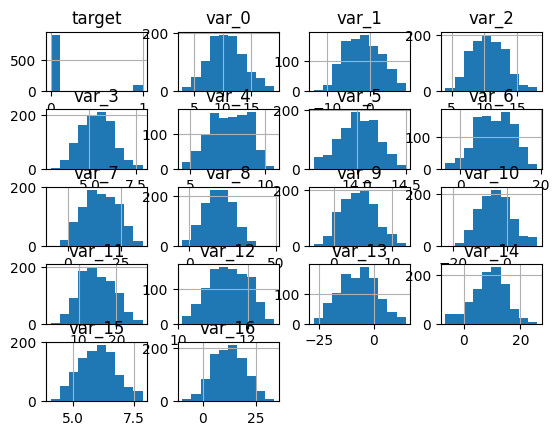

In [40]:
# Display a histogram
df.hist()

<Axes: >

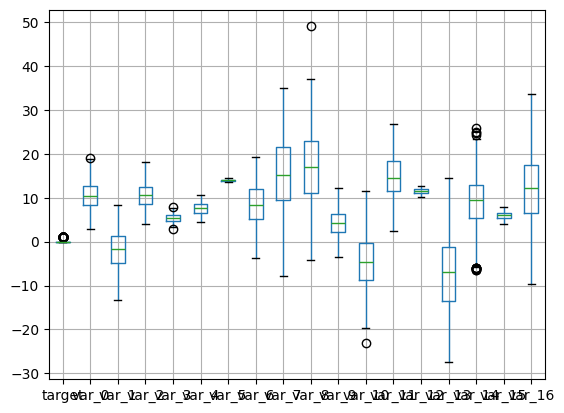

In [41]:
# display a boxplot
df.boxplot()

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [42]:
# column correlations
column_correlations = df.corr()
column_correlations

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
target,1.000000,-0.017817,0.101429,0.025716,-0.011348,-0.005215,-0.088978,-0.034422,0.028374,-0.030690,0.059438,0.024611,-0.088169,-0.034156,0.032045,-0.033832,0.009989,0.086618
var_0,-0.017817,1.000000,0.016709,0.033530,-0.041718,-0.029472,0.031765,-0.031768,0.053884,-0.001246,-0.041087,0.012658,0.040331,-0.016348,0.001870,-0.045511,-0.030945,0.000387
var_1,0.101429,0.016709,1.000000,0.054599,0.004523,-0.060222,0.029673,-0.009913,-0.013886,0.012571,0.019991,-0.015433,0.036771,-0.006590,0.050830,-0.054055,-0.002712,0.056096
var_2,0.025716,0.033530,0.054599,1.000000,-0.015892,0.007115,0.018316,-0.028780,-0.016959,-0.028103,0.031280,0.010854,0.011465,0.000913,-0.013533,0.012850,-0.059216,0.029235
var_3,-0.011348,-0.041718,0.004523,-0.015892,1.000000,-0.013690,0.005885,-0.001661,-0.018431,0.019194,0.033903,-0.025975,-0.021268,-0.029692,0.022048,-0.026840,-0.017160,-0.028598
var_4,-0.005215,-0.029472,-0.060222,0.007115,-0.013690,1.000000,-0.054929,0.018787,-0.048617,-0.025843,-0.002610,-0.009370,-0.015352,-0.040256,-0.023076,-0.011870,0.019113,-0.051219
var_5,-0.088978,0.031765,0.029673,0.018316,0.005885,-0.054929,1.000000,-0.003199,0.009396,0.009989,0.002301,-0.027920,0.003701,-0.023235,0.034798,0.013219,-0.037258,0.020763
var_6,-0.034422,-0.031768,-0.009913,-0.028780,-0.001661,0.018787,-0.003199,1.000000,-0.014602,-0.000257,0.005024,0.013592,-0.058749,-0.053371,-0.022342,-0.008460,0.001974,-0.002136
var_7,0.028374,0.053884,-0.013886,-0.016959,-0.018431,-0.048617,0.009396,-0.014602,1.000000,-0.067479,0.019505,0.025885,0.031629,-0.004120,0.009993,0.014491,0.011159,0.015657
var_8,-0.030690,-0.001246,0.012571,-0.028103,0.019194,-0.025843,0.009989,-0.000257,-0.067479,1.000000,0.016724,0.005545,-0.013643,-0.013057,0.060894,0.043611,-0.047564,-0.016875


<Axes: >

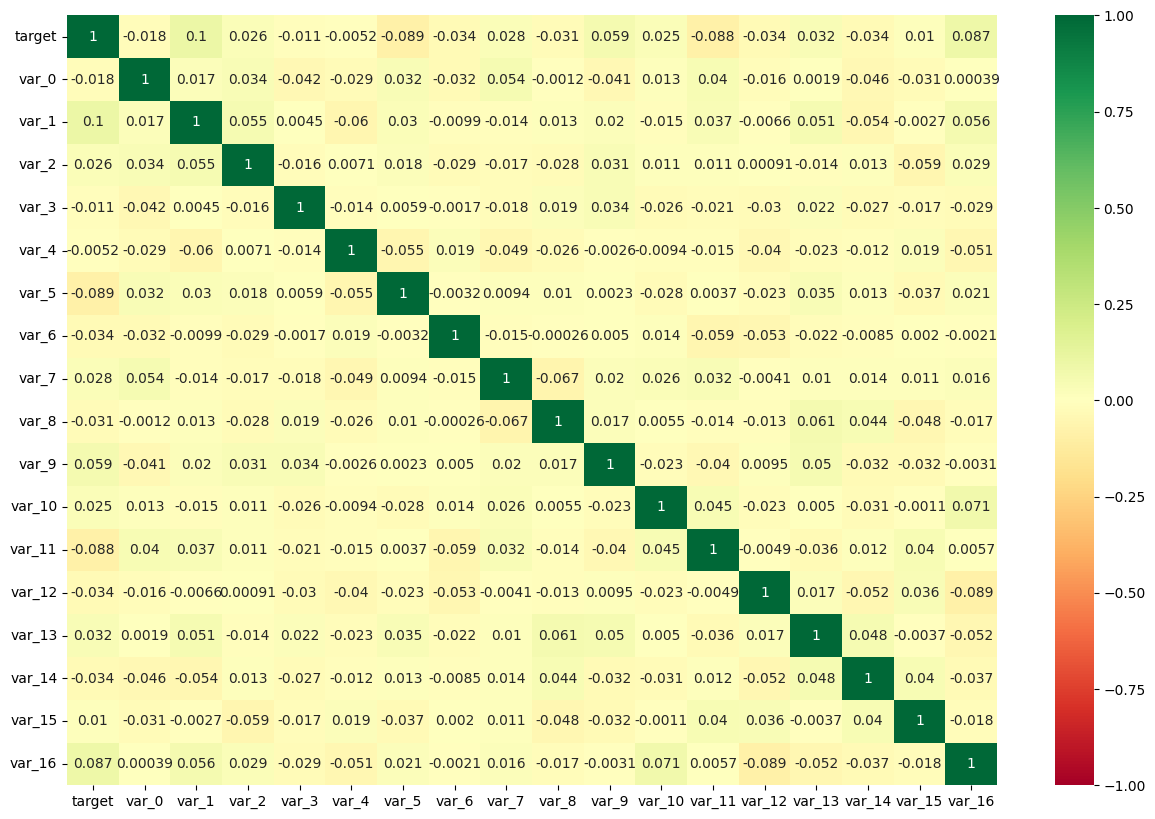

In [44]:
# Display correlation matrix
plt.figure(figsize = (15, 10))
sns.heatmap(
    column_correlations,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [45]:
# make successful (copy)
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
13,1,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,1.6565,-12.8761,14.3372,10.9481,-2.7683,6.9105,7.7886,16.2506
29,1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,4.3067,-12.6789,7.8550,11.2951,-15.7092,3.5497,5.7645,4.7981
63,1,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,9.3373,-5.2299,6.1225,10.8937,-1.7951,9.8521,6.7524,6.0510
65,1,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,3.9192,-0.4275,13.6590,11.7710,-5.8053,8.4739,5.1543,11.5268
71,1,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,9.6420,-2.8896,7.8835,10.7454,2.8668,5.0442,5.2764,21.6104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,1,7.6621,0.4167,10.4680,5.8456,9.2559,13.6211,15.6128,16.4877,9.0704,5.3054,-13.3659,6.1147,11.9022,-3.7101,14.4892,6.6341,9.4953
948,1,9.2188,-2.8367,11.2913,5.7660,6.3580,14.1106,13.9519,25.5899,4.0022,2.2490,-0.4429,11.1186,10.7792,5.3283,13.8381,7.1563,4.5899
953,1,10.9433,1.2270,11.1187,4.6052,5.8076,13.9011,12.9039,28.6617,11.5206,0.5991,-4.5676,11.4546,11.5790,7.5873,15.8396,4.8844,30.0818
954,1,10.1926,-5.9643,6.2806,4.5278,8.3062,14.2682,7.9985,27.9747,0.7939,1.2895,-11.4592,5.2892,11.5975,-14.7983,8.9196,6.0738,19.5625


In [46]:
# make unsuccessful (copy)
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


## Data Processing



### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [47]:
# make target and features
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [48]:
# check target
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [49]:
# check target value counts
target.value_counts()

,count
target,
0,903
1,97


In [50]:
# check target dimensions and type
type(target), target.shape, target.ndim

(pandas.core.series.Series, (1000,), 1)

In [51]:
# check features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


In [52]:
# check features dimensions and type
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (1000, 17), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [53]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [54]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [55]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [56]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [57]:
# Calculate the accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.892

#### 16. Present a confusion matrix and heatmap



Text(113.9222222222222, 0.5, 'Predicted')

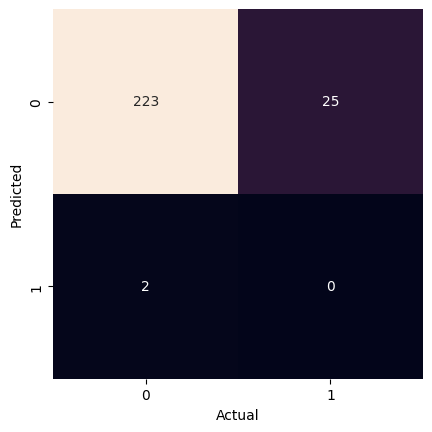

In [58]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [60]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0,0.899194,0.991111,0.942918,225.000
1,0.000000,0.000000,0.000000,25.000
accuracy,0.892000,0.892000,0.892000,0.892
macro avg,0.449597,0.495556,0.471459,250.000
weighted avg,0.809274,0.892000,0.848626,250.000


Conclusions (brief):

- adding more features increased the number of false positives from 0 to 2
- relative number of true negatives and false negatives about the same
- still no true positives (predicted transaction success and actually successful)

Future work:

- more data columns
- more balanced data set (downsampling of majority class?)